# Домашнее задание 8. Гравитационная модель и качество прогноза

**Оценивание.** `w8_hw.ipynb` весит 50% оценки. `w8_hw.tex` также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3д даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Рассчитай постоянные прогнозы, оцени гравитационную модель и её расширения, собери таблицы и построй графики ошибок. Интерпретацию, аргументы и итоговый вывод пиши в `w8_hw.tex`, ссылаясь на результаты этого блокнота.

Ты работаешь с одним товаром команды на уровне HS4 или HS6. Не нужно повторять паспорт товара из домашнего задания 3 и не нужно подгонять выводы под пример с мороженым.

## Для работы тебе пригодятся

Лонгрид недели 8 объясняет ошибку прогноза, MAE, RMSE, функцию потерь, линейную регрессию и $R^2$. Семинар показывает, как сравнивать прогнозы и разбирать ошибки гравитационной модели на примере мороженого. Материалы недели 7 понадобятся для стандартизации и кластеризации рынков.

В этом домашнем задании ты сравнишь гравитационную модель с простыми прогнозами, разберёшь её ошибки и проверишь, помогают ли характеристики импортных рынков. Если будет непонятно, что делать в конкретном блоке, вернись к соответствующему разделу лонгрида и к семинарским ячейкам с похожим расчётом.

В первой кодовой ячейке укажи `PRODUCT_LEVEL` и `PRODUCT_KEY`. В этой работе используй `SAMPLE_SIZE = 30` и `SELECTED_K = 3`. Число кластеров задано заранее, чтобы тестовые годы не участвовали в его выборе. Готовые функции убирают повторяющиеся циклы и оформление таблиц. Последовательность расчётов в каждом пункте напиши самостоятельно.

Торговые потоки, прогнозы, MAE, RMSE и дельты выражай в миллионах долларов. $R^2$ единиц измерения не имеет. Все модели сравнивай на одних и тех же наблюдениях.


In [1]:
# Запусти эту ячейку перед выполнением заданий
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

pd.options.display.float_format = "{:,.3f}".format

OEC_BASE_URL = "https://api-v2.oec.world/tesseract"
TRADE_CUBE = "trade_i_baci_a_17"
WDI_BASE_URL = "https://api.worldbank.org/v2"


def load_oec_data(drilldowns, include=None, measures="Trade Value", limit=50000):
    """Загружает таблицу из OEC/BACI"""
    params = {
        "cube": TRADE_CUBE,
        "drilldowns": ",".join(drilldowns),
        "measures": measures,
        "locale": "en",
        "parents": "false",
        "limit": f"{limit},0",
    }
    if include:
        params["include"] = ";".join(include)
    response = requests.get(
        f"{OEC_BASE_URL}/data.jsonrecords",
        params=params,
        timeout=120,
    )
    response.raise_for_status()
    table = pd.DataFrame(response.json()["data"])
    if table.empty:
        raise ValueError("OEC вернул пустую таблицу. Проверь код товара и уровень HS.")
    return table, response.url


def load_wdi_panel(indicator, value_name, start_year, end_year):
    """Загружает панель показателя World Development Indicators"""
    response = requests.get(
        f"{WDI_BASE_URL}/country/all/indicator/{indicator}",
        params={
            "format": "json",
            "date": f"{start_year}:{end_year}",
            "per_page": 20000,
        },
        timeout=120,
    )
    response.raise_for_status()
    payload = response.json()
    rows = [
        {
            "ISO3": item["countryiso3code"],
            "Year": int(item["date"]),
            value_name: item["value"],
        }
        for item in payload[1]
        if item["countryiso3code"] and item["value"] is not None
    ]
    return pd.DataFrame(rows), response.url


def load_country_coordinates():
    """Загружает координаты столиц и региональную классификацию World Bank"""
    response = requests.get(
        f"{WDI_BASE_URL}/country",
        params={"format": "json", "per_page": 400},
        timeout=120,
    )
    response.raise_for_status()
    rows = [
        {
            "ISO3": item["id"],
            "Страна WDI": item["name"],
            "Регион": item["region"]["value"],
            "Широта": pd.to_numeric(item["latitude"], errors="coerce"),
            "Долгота": pd.to_numeric(item["longitude"], errors="coerce"),
        }
        for item in response.json()[1]
    ]
    return pd.DataFrame(rows), response.url


def great_circle_distance(lat1, lon1, lat2, lon2):
    """Считает расстояние по дуге Земли в километрах"""
    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2],
    )
    value = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(value))


def load_gravity_panel(product_key, product_level="HS4", test_year_count=2):
    """Собирает мировые двусторонние потоки выбранного товара"""
    trade, trade_url = load_oec_data(
        ["Year", "Exporter Country", "Importer Country", product_level],
        [f"{product_level}:{product_key}"],
        limit=100000,
    )
    trade["ISO3 экспортёра"] = (
        trade["Exporter Country ID"].str[-3:].str.upper()
    )
    trade["ISO3 импортёра"] = (
        trade["Importer Country ID"].str[-3:].str.upper()
    )
    trade = (
        trade.groupby(
            [
                "Year",
                "ISO3 экспортёра",
                "Exporter Country",
                "ISO3 импортёра",
                "Importer Country",
            ],
            as_index=False,
        )["Trade Value"]
        .sum()
        .rename(
            columns={
                "Exporter Country": "Экспортёр",
                "Importer Country": "Импортёр",
                "Trade Value": "Торговый поток, долл",
            }
        )
    )

    first_year = int(trade["Year"].min())
    last_year = int(trade["Year"].max())
    gdp, gdp_url = load_wdi_panel(
        "NY.GDP.MKTP.CD", "ВВП, долл", first_year, last_year
    )
    income, income_url = load_wdi_panel(
        "NY.GDP.PCAP.CD", "Доход на душу, долл", first_year, last_year
    )
    coordinates, coordinates_url = load_country_coordinates()

    exporter_gdp = gdp.rename(
        columns={"ISO3": "ISO3 экспортёра", "ВВП, долл": "ВВП экспортёра, долл"}
    )
    importer_gdp = gdp.rename(
        columns={"ISO3": "ISO3 импортёра", "ВВП, долл": "ВВП импортёра, долл"}
    )
    importer_income = income.rename(
        columns={
            "ISO3": "ISO3 импортёра",
            "Доход на душу, долл": "Доход импортёра на душу, долл",
        }
    )
    exporter_coordinates = coordinates[["ISO3", "Широта", "Долгота"]].rename(
        columns={
            "ISO3": "ISO3 экспортёра",
            "Широта": "Широта экспортёра",
            "Долгота": "Долгота экспортёра",
        }
    )
    importer_coordinates = coordinates[["ISO3", "Широта", "Долгота"]].rename(
        columns={
            "ISO3": "ISO3 импортёра",
            "Широта": "Широта импортёра",
            "Долгота": "Долгота импортёра",
        }
    )

    panel = (
        trade.merge(exporter_gdp, on=["Year", "ISO3 экспортёра"], how="inner")
        .merge(importer_gdp, on=["Year", "ISO3 импортёра"], how="inner")
        .merge(importer_income, on=["Year", "ISO3 импортёра"], how="inner")
        .merge(exporter_coordinates, on="ISO3 экспортёра", how="inner")
        .merge(importer_coordinates, on="ISO3 импортёра", how="inner")
    )
    panel["Расстояние, км"] = great_circle_distance(
        panel["Широта экспортёра"],
        panel["Долгота экспортёра"],
        panel["Широта импортёра"],
        panel["Долгота импортёра"],
    )
    panel = panel.loc[
        (panel["Торговый поток, долл"] > 0)
        & (panel["ВВП экспортёра, долл"] > 0)
        & (panel["ВВП импортёра, долл"] > 0)
        & (panel["Доход импортёра на душу, долл"] > 0)
        & (panel["Расстояние, км"] > 0)
        & panel["ISO3 экспортёра"].ne(panel["ISO3 импортёра"])
    ].copy()
    panel["Торговый поток, млн долл"] = panel["Торговый поток, долл"] / 1e6
    panel["Доход импортёра на душу, тыс долл"] = (
        panel["Доход импортёра на душу, долл"] / 1000
    )

    years = sorted(panel["Year"].unique())
    if len(years) <= test_year_count:
        raise ValueError("Недостаточно лет для обучающей и тестовой выборок.")
    test_years = [int(year) for year in years[-test_year_count:]]
    panel = panel.sort_values(
        ["Year", "ISO3 экспортёра", "ISO3 импортёра"]
    ).reset_index(drop=True)

    test_years_text = ", ".join(map(str, test_years))
    note = (
        f"OEC/BACI: {first_year}–{last_year}; "
        f"тестовые годы: {test_years_text}; расстояние между столицами."
    )
    sources = {
        "OEC": trade_url,
        "World Bank GDP": gdp_url,
        "World Bank income": income_url,
        "World Bank coordinates": coordinates_url,
    }
    return panel, test_years, note, sources


def build_market_features(train_data, sample_size=30):
    """Повторяет признаки рынков недели 7 только по обучающему периоду"""
    market_by_year = (
        train_data.groupby(
            ["Year", "ISO3 импортёра", "Импортёр"], as_index=False
        )["Торговый поток, млн долл"]
        .sum()
    )
    years = sorted(market_by_year["Year"].unique())
    first_year, last_year = int(years[0]), int(years[-1])
    span = max(1, last_year - first_year)
    first = (
        market_by_year.loc[
            market_by_year["Year"].eq(first_year),
            ["ISO3 импортёра", "Торговый поток, млн долл"],
        ]
        .rename(columns={"Торговый поток, млн долл": "Первый импорт"})
    )
    last = (
        market_by_year.loc[
            market_by_year["Year"].eq(last_year),
            ["ISO3 импортёра", "Импортёр", "Торговый поток, млн долл"],
        ]
        .rename(columns={"Торговый поток, млн долл": "Импорт товара, млн долл"})
    )
    income = (
        train_data.loc[
            train_data["Year"].eq(last_year),
            ["ISO3 импортёра", "Доход импортёра на душу, тыс долл"],
        ]
        .drop_duplicates("ISO3 импортёра")
    )
    markets = first.merge(last, on="ISO3 импортёра").merge(
        income, on="ISO3 импортёра"
    )
    markets["Рост импорта, %"] = (
        (markets["Импорт товара, млн долл"] / markets["Первый импорт"])
        ** (1 / span)
        - 1
    ) * 100
    markets = markets.nlargest(sample_size, "Импорт товара, млн долл").copy()
    if len(markets) < sample_size:
        raise ValueError("Для кластеризации недостаточно рынков. Уменьши SAMPLE_SIZE.")
    return markets.drop(columns="Первый импорт").sort_values("ISO3 импортёра")


def regression_table(model, feature_names):
    """Возвращает константу и коэффициенты линейной регрессии"""
    return pd.DataFrame(
        {
            "Параметр": ["Константа", *feature_names],
            "Оценка": [model.intercept_, *model.coef_],
        }
    )


def calculate_metrics(actual, predicted):
    """Считает показатели качества для одного набора прогнозов"""
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R2": r2_score(actual, predicted),
    }


def split_train_test(data, test_years):
    """Разделяет таблицу по заранее выбранным тестовым годам"""
    first_test_year = min(test_years)
    train = data.loc[data["Year"] < first_test_year].copy()
    test = data.loc[data["Year"].isin(test_years)].copy()
    return train, test


def compare_samples(samples):
    """Собирает размеры нескольких выборок в одну таблицу"""
    rows = []
    for name, data in samples.items():
        country_pairs = data[["ISO3 экспортёра", "ISO3 импортёра"]].drop_duplicates()
        rows.append(
            {
                "Выборка": name,
                "Наблюдений": len(data),
                "Экспортёров": data["ISO3 экспортёра"].nunique(),
                "Импортёров": data["ISO3 импортёра"].nunique(),
                "Пар стран": len(country_pairs),
            }
        )
    return pd.DataFrame(rows).set_index("Выборка")


def add_log_columns(data, columns):
    """Добавляет логарифмы положительных столбцов по словарю имён"""
    result = data.copy()
    for source_column, log_column in columns.items():
        if result[source_column].le(0).any():
            raise ValueError(f"В столбце {source_column!r} есть неположительные значения.")
        result[log_column] = np.log(result[source_column])
    return result


def evaluate_forecasts(
    data,
    actual_column,
    forecast_columns,
    include_log_r2=True,
):
    """Сравнивает несколько прогнозов на одной выборке"""
    actual = data[actual_column]
    rows = []
    for model_name, prediction_column in forecast_columns.items():
        predicted = data[prediction_column]
        metrics = calculate_metrics(actual, predicted)
        if include_log_r2:
            metrics["R2 в логарифмах"] = r2_score(
                np.log(actual),
                np.log(predicted),
            )
        rows.append({"Модель": model_name, **metrics})
    return pd.DataFrame(rows).set_index("Модель")


def largest_forecast_errors(
    data,
    actual_column,
    forecast_columns,
    id_columns=("Year", "Экспортёр", "Импортёр"),
):
    """Находит крупнейшую абсолютную ошибку каждого прогноза"""
    rows = []
    for model_name, prediction_column in forecast_columns.items():
        absolute_error = (data[actual_column] - data[prediction_column]).abs()
        row_index = absolute_error.idxmax()
        row = data.loc[row_index, list(id_columns)].to_dict()
        rows.append(
            {
                "Модель": model_name,
                **row,
                "Факт": data.loc[row_index, actual_column],
                "Прогноз": data.loc[row_index, prediction_column],
                "Абсолютная ошибка": absolute_error.loc[row_index],
            }
        )
    return pd.DataFrame(rows)


def prediction_errors(data, actual_column, prediction_column):
    """Добавляет дельту, абсолютную и процентную ошибки прогноза"""
    result = data.copy()
    result["Дельта"] = result[actual_column] - result[prediction_column]
    result["Абсолютная дельта"] = result["Дельта"].abs()
    result["Дельта, % факта"] = 100 * result["Дельта"] / result[actual_column]
    return result.sort_values("Абсолютная дельта", ascending=False)


def plot_largest_deltas(errors, label_columns, n=20):
    """Строит график наблюдений с крупнейшими абсолютными дельтами"""
    plot_data = errors.head(n).sort_values("Дельта").copy()
    labels = plot_data[list(label_columns)].astype(str).agg("–".join, axis=1)
    colors = np.where(plot_data["Дельта"] >= 0, "#6087DC", "#E76F51")
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.barh(labels, plot_data["Дельта"], color=colors)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_xlabel("Факт минус прогноз, млн долл")
    ax.set_ylabel("–".join(label_columns))
    ax.set_title(f"{n} крупнейших абсолютных дельт")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()


def grouped_prediction_errors(errors, group_columns, n=10):
    """Считает среднюю дельту, MAE и RMSE по группам"""
    result = errors.groupby(group_columns).agg(
        Наблюдений=("Дельта", "size"),
        Средняя_дельта=("Дельта", "mean"),
        MAE=("Абсолютная дельта", "mean"),
        MSE=("Дельта", lambda values: np.mean(values**2)),
    )
    result["RMSE"] = np.sqrt(result.pop("MSE"))
    return result.sort_values("RMSE", ascending=False).head(n)


def attach_group_labels(train, test, lookup, key, group_column):
    """Присоединяет одни и те же метки групп к двум выборкам"""
    labels = lookup[[key, group_column]].drop_duplicates(key)
    train_with_groups = train.merge(
        labels, on=key, how="inner", validate="many_to_one"
    )
    test_with_groups = test.merge(
        labels, on=key, how="inner", validate="many_to_one"
    )
    return train_with_groups, test_with_groups


def aligned_dummies(train_values, test_values, prefix):
    """Создаёт согласованные индикаторы категорий для train и test"""
    train_dummies = pd.get_dummies(
        train_values, prefix=prefix, drop_first=True, dtype=float
    )
    test_dummies = pd.get_dummies(
        test_values, prefix=prefix, drop_first=True, dtype=float
    ).reindex(columns=train_dummies.columns, fill_value=0)
    return train_dummies, test_dummies


def largest_error_comparison(
    data,
    actual_column,
    forecast_columns,
    reference_model,
    n=20,
):
    """Сравнивает модели на наблюдениях, трудных для опорной модели"""
    id_columns = ["Year", "Экспортёр", "Импортёр", actual_column]
    result = data[[*id_columns, *forecast_columns.values()]].copy()
    for model_name, prediction_column in forecast_columns.items():
        result[f"Абсолютная ошибка: {model_name}"] = (
            result[actual_column] - result[prediction_column]
        ).abs()
    return result.nlargest(n, f"Абсолютная ошибка: {reference_model}")


def cluster_markets(markets, feature_columns, n_clusters):
    """Стандартизирует признаки и присваивает рынкам кластеры"""
    result = markets.copy()
    scaler = StandardScaler()
    feature_matrix = scaler.fit_transform(result[feature_columns])
    model = KMeans(n_clusters=n_clusters, n_init=30, random_state=42)
    result["Кластер"] = model.fit_predict(feature_matrix) + 1
    return result, scaler, model


def fit_log_model(train_features, train_target, test_features):
    """Оценивает линейную модель для логарифма и возвращает прогноз в уровнях"""
    model = LinearRegression(fit_intercept=True)
    model.fit(train_features, train_target)
    coefficients = regression_table(model, train_features.columns)
    prediction = np.exp(model.predict(test_features))
    return model, coefficients, prediction


def evaluate_forecasts_by_group(
    data,
    group_column,
    actual_column,
    forecast_columns,
):
    """Сравнивает одни и те же прогнозы внутри нескольких групп"""
    tables = []
    for group, group_data in data.groupby(group_column):
        metrics = evaluate_forecasts(
            group_data,
            actual_column,
            forecast_columns,
        ).reset_index()
        metrics.insert(0, group_column, group)
        tables.append(metrics)
    return pd.concat(tables, ignore_index=True).set_index(
        [group_column, "Модель"]
    )


# Параметры работы: укажи код товара, остальные значения оставь заданными
PRODUCT_LEVEL = "HS4"  # Фанера, как в неделе 7
PRODUCT_KEY = "94412"  # В OEC перед кодом HS4 стоит номер раздела (9)
SAMPLE_SIZE = 30
SELECTED_K = 3  # Число групп зафиксировано до проверки на тестовых годах


## **[Синий, 2 балла]** Задание 1. Простые прогнозы

### **[Синий, 1 балл]** Пункт 1а. Обучающая и тестовая выборки

Прежде чем строить модель, нужно понять, какой результат она должна превзойти. Представь прогноз, который ничего не знает о странах и назначает один и тот же поток любой паре. Среднее и медиана дадут два таких ориентира. Позже мы проверим, приносит ли гравитационная модель пользу по сравнению с ними.

Загрузи данные вызовом `load_gravity_panel()` и раздели их через `split_train_test()`. Собери размеры выборок с помощью `compare_samples()`. Для торгового потока, ВВП экспортёра, ВВП импортёра и расстояния создай `data_diagnostics` через `describe().T`. Затем рассчитай по `train_data` среднее и медиану и добавь два постоянных прогноза в `test_data`. В `baseline_predictions` оставь год, экспортёра, импортёра, фактический поток и оба прогноза; строки упорядочи по фактическому потоку от большего к меньшему.

Среднее и медиану считай только по обучающей выборке. Тестовые значения не должны участвовать в построении прогноза.

**Что получить на выходе.** `train_data`, `test_data`, `sample_sizes`, `data_diagnostics`, два постоянных прогноза и `baseline_predictions`.


In [2]:
# Загрузи gravity_data и раздели таблицу через split_train_test()
gravity_data, TEST_YEARS, data_note, data_sources = load_gravity_panel(PRODUCT_KEY, PRODUCT_LEVEL)
train_data, test_data = split_train_test(gravity_data, TEST_YEARS)
print("Товар: фанера, HS4 4412, классификация HS 2017 (ключ OEC 94412)")
print(data_note)

# Создай sample_sizes и data_diagnostics для указанных в задании столбцов
sample_sizes = compare_samples({
    "Вся панель": gravity_data,
    "Обучающая": train_data,
    "Тестовая": test_data,
})
display(sample_sizes)

ACTUAL = "Торговый поток, млн долл"
DIAGNOSTIC_COLUMNS = [ACTUAL, "ВВП экспортёра, долл", "ВВП импортёра, долл", "Расстояние, км"]
data_diagnostics = train_data[DIAGNOSTIC_COLUMNS].describe().T
display(data_diagnostics)

# Насколько поток сосредоточен в крупных маршрутах
train_sorted = train_data[ACTUAL].sort_values(ascending=False)
top_share = train_sorted.head(int(len(train_sorted) * 0.01)).sum() / train_sorted.sum()
print(f"1% крупнейших потоков в обучающей выборке дают {top_share:.1%} всей торговли")

# Рассчитай среднее и медиану по train_data, добавь два прогноза в test_data
mean_flow = train_data[ACTUAL].mean()
median_flow = train_data[ACTUAL].median()
test_data["Прогноз средним"] = mean_flow
test_data["Прогноз медианой"] = median_flow
print(f"Среднее по обучающей выборке: {mean_flow:.3f} млн долл")
print(f"Медиана по обучающей выборке: {median_flow:.3f} млн долл")

# Собери baseline_predictions
baseline_predictions = test_data[
    ["Year", "Экспортёр", "Импортёр", ACTUAL, "Прогноз средним", "Прогноз медианой"]
].sort_values(ACTUAL, ascending=False)
display(baseline_predictions.head(10))


Товар: фанера, HS4 4412, классификация HS 2017 (ключ OEC 94412)
OEC/BACI: 2018–2024; тестовые годы: 2023, 2024; расстояние между столицами.


,Наблюдений,Экспортёров,Импортёров,Пар стран
Выборка,,,,
Вся панель,29607,191,200,7390
Обучающая,21164,188,200,6633
Тестовая,8443,168,194,5128


,count,mean,std,min,25%,50%,75%,max
"Торговый поток, млн долл","21,164.000",4.018,26.452,0.000,0.011,0.086,0.663,792.746
"ВВП экспортёра, долл","21,164.000","2,222,024,271,802.704","4,887,396,558,960.294","180,671,357.350","161,184,691,013.835","473,221,298,968.216","1,743,728,952,156.850","26,054,614,000,000.000"
"ВВП импортёра, долл","21,164.000","1,240,897,464,286.395","3,685,575,236,240.236","48,026,990.194","34,186,180,699.026","213,298,873,494.394","631,693,331,300.776","26,054,614,000,000.000"
"Расстояние, км","21,164.000","5,310.412","4,330.922",54.521,"1,600.016","4,167.845","8,277.876","19,854.735"


1% крупнейших потоков в обучающей выборке дают 51.6% всей торговли
Среднее по обучающей выборке: 4.018 млн долл
Медиана по обучающей выборке: 0.086 млн долл


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз средним,Прогноз медианой
29560,2024,Vietnam,United States,520.855,4.018,0.086
21784,2023,Canada,United States,468.645,4.018,0.086
26054,2024,Canada,United States,459.909,4.018,0.086
23243,2023,Indonesia,Japan,441.507,4.018,0.086
27441,2024,Indonesia,Japan,440.551,4.018,0.086
27487,2024,Indonesia,United States,414.490,4.018,0.086
25454,2023,Vietnam,United States,369.506,4.018,0.086
26168,2024,China,Australia,338.438,4.018,0.086
23286,2023,Indonesia,United States,333.327,4.018,0.086
24036,2023,Malaysia,Japan,332.206,4.018,0.086


**Что видим.** Панель OEC/BACI за 2018–2024 годы: учу модели на 2018–2022 (21 164 потока, 188 экспортёров, 200 импортёров), проверяю на 2023–2024 (8 443 потока, 5 128 пар стран). Поток сильно скошен: медиана 0,086 млн долл., среднее 4,02 млн, максимум 793 млн. 1% крупнейших потоков даёт 51,6% всей торговли. ВВП различаются на пять порядков, расстояние — от 55 до 19 855 км. Поэтому два постоянных прогноза очень разные: среднее в 47 раз больше медианы.

### **[Синий, 1 балл]** Пункт 1б. Метрики постоянных прогнозов

Торговые потоки могут быть распределены неравномерно: несколько маршрутов иногда заметно превосходят остальные. Тогда один постоянный прогноз будет чаще ошибаться понемногу, а другой — реже, но намного сильнее. Сопоставление MAE и RMSE покажет, наблюдается ли такое различие для товара твоей команды и как оно влияет на выбор ориентира.

Собери названия двух прогнозов в словарь `BASELINE_FORECASTS`: ключ задаёт название модели в итоговой таблице, а значение — название столбца с прогнозом в `test_data`. Рассчитай `baseline_metrics` через `evaluate_forecasts()`. Через `largest_forecast_errors()` создай `baseline_largest_errors` с одной строкой для каждого прогноза — наблюдением с его наибольшей абсолютной ошибкой.

Сравнивай прогнозы на одной тестовой выборке. Не выбирай лучшее правило до расчёта всех показателей.

**Что получить на выходе.** `baseline_metrics` и `baseline_largest_errors` с годом, экспортёром, импортёром, фактом, прогнозом и абсолютной ошибкой.


In [3]:
# Создай словарь BASELINE_FORECASTS
BASELINE_FORECASTS = {
    "Среднее": "Прогноз средним",
    "Медиана": "Прогноз медианой",
}

# Рассчитай baseline_metrics и baseline_largest_errors готовыми функциями
baseline_metrics = evaluate_forecasts(test_data, ACTUAL, BASELINE_FORECASTS)
display(baseline_metrics)

baseline_largest_errors = largest_forecast_errors(test_data, ACTUAL, BASELINE_FORECASTS)
display(baseline_largest_errors)

# Сколько тестовых потоков меньше среднего: столько раз среднее завышает прогноз
below_mean = (test_data[ACTUAL] < mean_flow).mean()
print(f"Потоков меньше среднего в тесте: {below_mean:.1%}")


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,6.344,22.437,-0.000,-1.440
Медиана,3.787,22.742,-0.028,-0.004


,Модель,Year,Экспортёр,Импортёр,Факт,Прогноз,Абсолютная ошибка
0,Среднее,2024,Vietnam,United States,520.855,4.018,516.837
1,Медиана,2024,Vietnam,United States,520.855,0.086,520.769


Потоков меньше среднего в тесте: 89.7%


**Что видим.** Медиана лучше по MAE (3,79 против 6,34 млн долл.), среднее — по RMSE (22,44 против 22,74). 89,7% тестовых потоков меньше среднего, так что среднее почти всегда завышает и проигрывает по средней ошибке. Зато на гигантских маршрутах оно промахивается чуть меньше, а RMSE штрафует эти промахи в квадрате. $R^2$ в уровнях у обоих около нуля (−0,000 и −0,028), так и должно быть у константы. В логарифмах медиана почти в нуле (−0,004), среднее уходит в −1,44. Самый большой промах у обоих один и тот же: Вьетнам → США в 2024 году, 521 млн долл.

## **[Синий, 3 балла; Красный, 1 балл]** Задание 2. Классическая гравитационная модель

### **[Синий, 1 балл]** Пункт 2а. Оценивание модели

Постоянный прогноз не различает крупную и небольшую экономику, близкую и далёкую страну. Гравитационная модель вводит эти различия в одну функцию: размер экономик должен поддерживать торговлю, а расстояние — сдерживать её. По оценённым коэффициентам можно проверить, совпадает ли наблюдаемая зависимость с этой логикой.

Добавь логарифмы в обе выборки через `add_log_columns()`. Затем задай три признака `GRAVITY_FEATURES`, создай `gravity_model` и оцени её по `train_data`:

$$
\ln Trade_{ijt}=b_0+b_1\ln GDP_{it}+b_2\ln GDP_{jt}+b_3\ln Distance_{ij}+u_{ijt}.
$$

Используй `LinearRegression(fit_intercept=True)`. Сохрани признаки в `GRAVITY_FEATURES`, модель в `gravity_model`, коэффициенты в `gravity_coefficients` и $R^2$ в логарифмах на обучающей выборке в `train_r2_log`.

На этом шаге не добавляй доход, кластеры и другие признаки. `train_r2_log` описывает подгонку модели на обучающей выборке, но ещё не показывает качество на более поздних наблюдениях.

**Что получить на выходе.** Оценённую модель, таблицу коэффициентов и обучающий $R^2$.


In [4]:
# Добавь логарифмы через add_log_columns()
LOG_COLUMNS = {
    ACTUAL: "ln Поток",
    "ВВП экспортёра, долл": "ln ВВП экспортёра",
    "ВВП импортёра, долл": "ln ВВП импортёра",
    "Расстояние, км": "ln Расстояние",
}
train_data = add_log_columns(train_data, LOG_COLUMNS)
test_data = add_log_columns(test_data, LOG_COLUMNS)

# Задай GRAVITY_FEATURES и самостоятельно оцени gravity_model
GRAVITY_FEATURES = ["ln ВВП экспортёра", "ln ВВП импортёра", "ln Расстояние"]
gravity_model = LinearRegression(fit_intercept=True)
gravity_model.fit(train_data[GRAVITY_FEATURES], train_data["ln Поток"])

# Сохрани gravity_coefficients и train_r2_log
gravity_coefficients = regression_table(gravity_model, GRAVITY_FEATURES)
display(gravity_coefficients)

train_r2_log = gravity_model.score(train_data[GRAVITY_FEATURES], train_data["ln Поток"])
print(f"R2 в логарифмах на обучающей выборке: {train_r2_log:.3f}")


,Параметр,Оценка
0,Константа,-18.765
1,ln ВВП экспортёра,0.512
2,ln ВВП импортёра,0.404
3,ln Расстояние,-0.990


R2 в логарифмах на обучающей выборке: 0.154


**Что видим.** Знаки совпали с теорией: ВВП экспортёра +0,51, ВВП импортёра +0,40, расстояние −0,99. Если расстояние больше на 1%, поток в среднем меньше примерно на 1%. Но $R^2$ на обучении всего 0,154: размер экономик и расстояние объясняют 15% разброса логарифма потока. Для одного товара это ожидаемо, фанеру продают те, у кого есть лес и заводы, а не просто большие экономики.

### **[Синий, 1 балл]** Пункт 2б. Прогноз на более поздних наблюдениях

Даже подходящее уравнение может хорошо описывать годы, на которых его оценили, и хуже работать позднее. Поэтому теперь важны не коэффициенты сами по себе, а прогноз для наблюдений, которых модель не видела при обучении. Именно на них гравитационную модель можно честно сопоставить с постоянными ориентирами.

Получи прогноз логарифма торгового потока для `test_data`, затем верни его в миллионы долларов с помощью экспоненты. Запиши результат в `Прогноз гравитационной модели`. Модель получает фактические значения ВВП за тестовый год, поэтому это условный прогноз потока на более поздних наблюдениях при известных признаках.

Рассчитай MAE, RMSE и $R^2$ в миллионах долларов, а также $R^2$ в логарифмах. Добавь модель к двум постоянным прогнозам в таблице `model_comparison`.

В этой работе используй простое обратное преобразование через экспоненту. Дополнительную поправку считать не нужно.

**Что получить на выходе.** Прогноз для каждой пары стран, `prediction_table` и `model_comparison` из трёх строк.


In [5]:
# Получи прогноз gravity_model для test_data и примени np.exp()
log_prediction = gravity_model.predict(test_data[GRAVITY_FEATURES])
test_data["Прогноз гравитационной модели"] = np.exp(log_prediction)

# Собери ALL_FORECASTS, model_comparison и prediction_table
ALL_FORECASTS = {
    **BASELINE_FORECASTS,
    "Гравитационная модель": "Прогноз гравитационной модели",
}
model_comparison = evaluate_forecasts(test_data, ACTUAL, ALL_FORECASTS)
display(model_comparison)

prediction_table = test_data[
    ["Year", "Экспортёр", "Импортёр", ACTUAL, *ALL_FORECASTS.values()]
].sort_values(ACTUAL, ascending=False)
display(prediction_table.head(10))

# Сумма прогнозов против суммы факта: после exp модель занижает общий объём
total_actual = test_data[ACTUAL].sum()
total_gravity = test_data["Прогноз гравитационной модели"].sum()
print(f"Сумма факта: {total_actual:,.0f} млн долл, сумма прогноза модели: {total_gravity:,.0f} млн долл")


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Среднее,6.344,22.437,-0.000,-1.440
Медиана,3.787,22.742,-0.028,-0.004
Гравитационная модель,3.730,22.631,-0.017,0.138


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз средним,Прогноз медианой,Прогноз гравитационной модели
29560,2024,Vietnam,United States,520.855,4.018,0.086,0.151
21784,2023,Canada,United States,468.645,4.018,0.086,5.707
26054,2024,Canada,United States,459.909,4.018,0.086,5.928
23243,2023,Indonesia,Japan,441.507,4.018,0.086,0.275
27441,2024,Indonesia,Japan,440.551,4.018,0.086,0.273
27487,2024,Indonesia,United States,414.490,4.018,0.086,0.214
25454,2023,Vietnam,United States,369.506,4.018,0.086,0.141
26168,2024,China,Australia,338.438,4.018,0.086,0.467
23286,2023,Indonesia,United States,333.327,4.018,0.086,0.208
24036,2023,Malaysia,Japan,332.206,4.018,0.086,0.159


Сумма факта: 32,151 млн долл, сумма прогноза модели: 1,621 млн долл


**Что видим.** По MAE гравитационная модель лучшая (3,73 против 3,79 у медианы и 6,34 у среднего), в логарифмах $R^2$ 0,138 против примерно нуля у медианы. По RMSE она хуже среднего (22,63 против 22,44), $R^2$ в уровнях −0,017. Причина видна в `prediction_table`: самые крупные маршруты (Вьетнам → США 521 млн, Индонезия → Япония 442 млн) модель оценивает в 0,15–0,28 млн. Экспонента от прогноза логарифма ближе к медиане, чем к среднему, поэтому сумма прогнозов 1 621 млн долл. при факте 32 151 млн, в 20 раз меньше. Типичный маленький поток модель угадывает неплохо, крупнейших поставщиков не видит совсем.

### **[Синий, 1 балл]** Пункт 2в. Дельты по торговым потокам

Одна итоговая метрика сворачивает тысячи прогнозов в одно число и скрывает конкретные маршруты. Дельта возвращает нас от средней оценки к отдельной паре стран. По её знаку видно, недооценила модель поток или, наоборот, ожидала слишком много торговли.

Создай `prediction_deltas` вызовом `prediction_errors()`. Затем передай таблицу и столбцы для подписей в `plot_largest_deltas()`, чтобы построить диаграмму для 20 крупнейших абсолютных дельт. В подписи укажи экспортёра, импортёра и год. Положительная дельта означает, что модель занизила поток, отрицательная — завысила.

Процентную дельту не используй как основной показатель при фактическом потоке, близком к нулю.

**Что получить на выходе.** `prediction_deltas` и график 20 крупнейших промахов.


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта,"Дельта, % факта"
29560,2024,Vietnam,United States,520.855,0.151,520.704,99.971
21784,2023,Canada,United States,468.645,5.707,462.938,98.782
26054,2024,Canada,United States,459.909,5.928,453.981,98.711
23243,2023,Indonesia,Japan,441.507,0.275,441.232,99.938
27441,2024,Indonesia,Japan,440.551,0.273,440.278,99.938


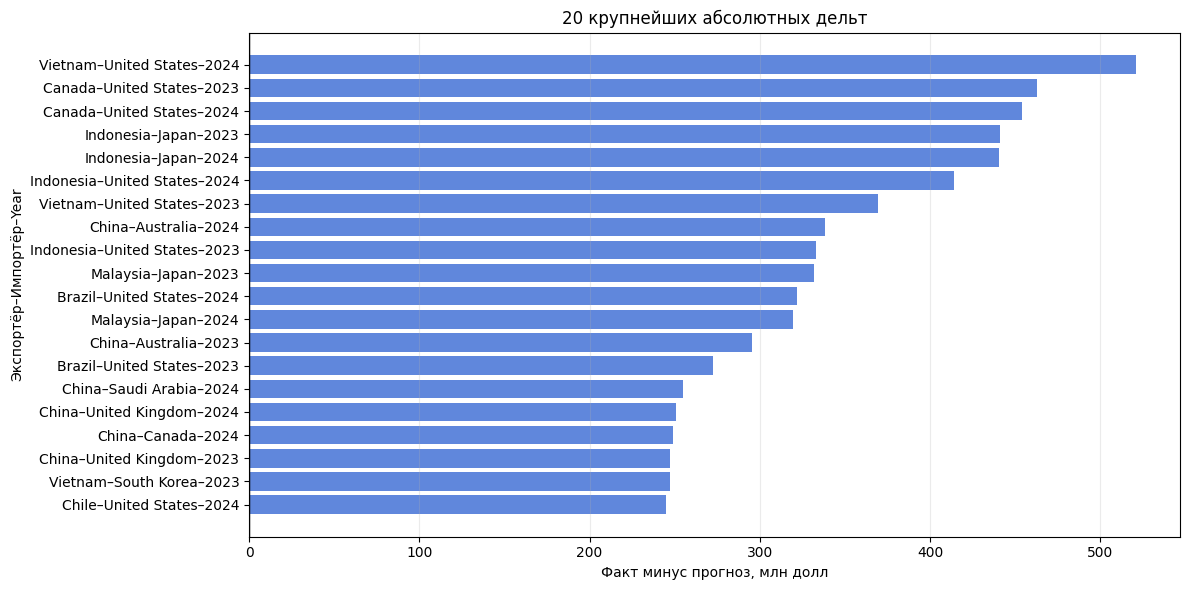

Из 20 крупнейших промахов модель занизила поток в 20 случаях


In [6]:
# Создай prediction_deltas через prediction_errors()
prediction_deltas = prediction_errors(test_data, ACTUAL, "Прогноз гравитационной модели")
display(prediction_deltas[
    ["Year", "Экспортёр", "Импортёр", ACTUAL, "Прогноз гравитационной модели",
     "Дельта", "Дельта, % факта"]
].head(5))

# Построй график вызовом plot_largest_deltas()
plot_largest_deltas(prediction_deltas, ["Экспортёр", "Импортёр", "Year"], n=20)

top20 = prediction_deltas.head(20)
print(f"Из 20 крупнейших промахов модель занизила поток в {(top20['Дельта'] > 0).sum()} случаях")


**Что видим.** Все 20 крупнейших промахов — занижение (дельта положительная). Это поставки от крупных производителей фанеры — Вьетнама, Канады, Индонезии, Малайзии, Китая, Бразилии, Чили — в США, Японию, Австралию, Великобританию. Процентная дельта на них около 99%, то есть модель даёт почти ноль. Одни и те же пары стоят в списке в оба тестовых года, значит ошибка устойчивая, а не разовый скачок.

### **[Красный, 1 балл]** Пункт 2г. Где сосредоточены ошибки

Если крупные промахи снова и снова связаны с одними импортёрами, общей формуле может не хватать характеристик этих рынков. Сначала нужно обнаружить такое повторение в ошибках. Оно подскажет направление следующей проверки, но ещё не назовёт причину.

Для столбцов `Дельта` и `Абсолютная дельта` создай `delta_diagnostics` через `describe().T`. В `largest_errors` сохрани десять наблюдений с наибольшей абсолютной дельтой. Затем вызови `grouped_prediction_errors()`, сгруппировав строки по коду и названию импортёра, и сохрани результат в `importer_errors`. Функция вернёт десять импортёров с наибольшим RMSE.

Групповая таблица описывает расположение ошибок, но сама по себе не устанавливает их причину.

**Что получить на выходе.** `delta_diagnostics`, `largest_errors` и `importer_errors`.


In [7]:
# Создай delta_diagnostics и выбери largest_errors по абсолютной дельте
delta_diagnostics = prediction_deltas[["Дельта", "Абсолютная дельта"]].describe().T
display(delta_diagnostics)

largest_errors = prediction_deltas.head(10)[
    ["Year", "Экспортёр", "Импортёр", ACTUAL, "Прогноз гравитационной модели", "Дельта"]
]
display(largest_errors)

# Рассчитай importer_errors через grouped_prediction_errors()
importer_errors = grouped_prediction_errors(prediction_deltas, ["ISO3 импортёра", "Импортёр"])
display(importer_errors)

# Какую долю всей абсолютной ошибки дают эти десять импортёров
error_by_importer = prediction_deltas.groupby("ISO3 импортёра")["Абсолютная дельта"].sum()
top10_importers = importer_errors.index.get_level_values("ISO3 импортёра")
top10_error_share = error_by_importer.loc[top10_importers].sum() / error_by_importer.sum()
print(f"10 импортёров с наибольшим RMSE дают {top10_error_share:.1%} суммы абсолютных дельт")

# Отдельно смотрю российские поставки на рынки, выбранные командой
OUR_MARKETS = ["KOR", "IND", "SAU", "CHN", "EGY"]
russia_flows = prediction_deltas.loc[
    prediction_deltas["ISO3 экспортёра"].eq("RUS")
    & prediction_deltas["ISO3 импортёра"].isin(OUR_MARKETS),
    ["Year", "Импортёр", ACTUAL, "Прогноз гравитационной модели", "Дельта"],
].sort_values(["Импортёр", "Year"])
display(russia_flows)


,count,mean,std,min,25%,50%,75%,max
Дельта,"8,443.000",3.616,22.341,-3.355,-0.055,0.011,0.494,520.704
Абсолютная дельта,"8,443.000",3.730,22.322,0.000,0.038,0.120,0.572,520.704


,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта
29560,2024,Vietnam,United States,520.855,0.151,520.704
21784,2023,Canada,United States,468.645,5.707,462.938
26054,2024,Canada,United States,459.909,5.928,453.981
23243,2023,Indonesia,Japan,441.507,0.275,441.232
27441,2024,Indonesia,Japan,440.551,0.273,440.278
27487,2024,Indonesia,United States,414.490,0.214,414.276
25454,2023,Vietnam,United States,369.506,0.141,369.365
26168,2024,China,Australia,338.438,0.467,337.971
23286,2023,Indonesia,United States,333.327,0.208,333.120
24036,2023,Malaysia,Japan,332.206,0.159,332.047


,,Наблюдений,Средняя_дельта,MAE,RMSE
ISO3 импортёра,Импортёр,,,,
USA,United States,153,37.876,37.950,103.573
JPN,Japan,83,25.678,25.789,90.725
KOR,South Korea,80,16.968,17.116,52.815
AUS,Australia,99,10.049,10.076,46.130
MYS,Malaysia,61,12.909,12.997,41.945
MEX,Mexico,69,13.206,13.255,39.351
PHL,Philippines,59,9.604,9.722,35.526
GBR,United Kingdom,127,9.870,10.113,35.165
SAU,Saudi Arabia,114,6.604,6.735,34.539


10 импортёров с наибольшим RMSE дают 48.0% суммы абсолютных дельт


,Year,Импортёр,"Торговый поток, млн долл",Прогноз гравитационной модели,Дельта
24602,2023,China,134.064,0.603,133.461
28732,2024,China,173.583,0.630,172.953
24611,2023,Egypt,212.504,0.254,212.250
28739,2024,Egypt,132.256,0.261,131.995
24623,2023,India,8.497,0.410,8.086
28745,2024,India,12.391,0.437,11.954
24646,2023,Saudi Arabia,17.659,0.329,17.330
28764,2024,Saudi Arabia,13.923,0.344,13.579
24630,2023,South Korea,44.172,0.209,43.963
28752,2024,South Korea,93.494,0.218,93.277


**Что видим.** Медиана дельты 0,011 млн долл., на типичном маршруте модель почти не ошибается. Но среднее 3,6, стандартное отклонение 22,3 и максимум 521: ошибка сидит в хвосте. Минимальная дельта всего −3,4, так что завышает модель мало, промахи почти только в сторону занижения. 10 импортёров с наибольшим RMSE (США 103,6, Япония 90,7, Корея 52,8, затем Австралия, Малайзия, Мексика, Филиппины, Великобритания, Саудовская Аравия, Египет) дают 48,0% суммы абсолютных дельт. У всех средняя дельта почти равна MAE: импорт этих стран модель занижает систематически. Корея, Саудовская Аравия и Египет — рынки из нашего отчёта. Российские поставки модель тоже занижает в сотни раз: в Египет 212,5 млн в 2023 году при прогнозе 0,25 млн, в Китай 173,6 млн в 2024 году при 0,63, в Корею 93,5 млн при 0,22. В модели нет ничего, что говорило бы, что Россия — крупный производитель берёзовой фанеры.

## **[Красный, 1 балл; чёрный, 3 балла + 1 бонусный балл]** Задание 3. Дополнительные признаки

### **[Красный, 1 балл]** Пункт 3а. Кластеры рынков без информации из теста

Разбор ошибок вернул нас к идее прошлой недели: импортные рынки различаются не по одному показателю, а по сочетанию размера, динамики и дохода. Кластеры превратят эти сочетания в несколько типов рынков. Чтобы проверка оставалась честной, будущие для модели годы не должны участвовать в создании этих типов.

Вызови `build_market_features(train_data, SAMPLE_SIZE)`. Полученная таблица повторяет три признака недели 7: импорт товара, рост импорта и доход на душу населения. Все они рассчитаны только по обучающему периоду.

Добавь столбец `Логарифм импорта` по формуле $\ln(1+M)$ с помощью `np.log1p()`. В `CLUSTER_FEATURES` включи логарифм импорта, рост импорта и доход на душу населения. Построй три группы вызовом `cluster_markets()`. В `cluster_profiles` для каждого кластера укажи число стран и средние значения импорта, роста и дохода в исходных единицах. Затем через `attach_group_labels()` создай `extension_train` и `extension_test`. Все модели дальше сравнивай только на этой общей выборке отобранных рынков.

**Что получить на выходе.** `market_features`, `cluster_profiles`, `extension_train` и `extension_test`.


In [8]:
# Создай market_features, добавь ln(1 + импорт) и задай CLUSTER_FEATURES
market_features = build_market_features(train_data, SAMPLE_SIZE)
market_features["Логарифм импорта"] = np.log1p(market_features["Импорт товара, млн долл"])
CLUSTER_FEATURES = ["Логарифм импорта", "Рост импорта, %", "Доход импортёра на душу, тыс долл"]
train_years = sorted(train_data["Year"].unique())
print(f"Признаки рынков: импорт за {train_years[-1]}, рост за {train_years[0]}–{train_years[-1]}")

# Построй кластеры вызовом cluster_markets() и рассчитай cluster_profiles
market_clusters, cluster_scaler, cluster_kmeans = cluster_markets(
    market_features, CLUSTER_FEATURES, SELECTED_K
)

# Номера KMeans случайные, перенумерую по убыванию среднего импорта.
# Тогда кластер 1 (группа сравнения в пункте 3в) — самые крупные рынки.
order = market_clusters.groupby("Кластер")["Логарифм импорта"].mean().sort_values(ascending=False).index
renumber = {old: new for new, old in enumerate(order, start=1)}
market_clusters["Кластер"] = market_clusters["Кластер"].map(renumber)

cluster_profiles = market_clusters.groupby("Кластер").agg(
    Стран=("ISO3 импортёра", "size"),
    Импорт_млн_долл=("Импорт товара, млн долл", "mean"),
    Рост_импорта_проц=("Рост импорта, %", "mean"),
    Доход_тыс_долл=("Доход импортёра на душу, тыс долл", "mean"),
)
display(cluster_profiles)

members = (
    market_clusters.sort_values("Импорт товара, млн долл", ascending=False)
    .groupby("Кластер")["ISO3 импортёра"]
    .apply(", ".join)
)
for cluster, countries in members.items():
    print(f"Кластер {cluster}: {countries}")

# Присоедини группы к train_data и test_data через attach_group_labels()
extension_train, extension_test = attach_group_labels(
    train_data, test_data, market_clusters, "ISO3 импортёра", "Кластер"
)
display(compare_samples({"Общая обучающая": extension_train, "Общая тестовая": extension_test}))
common_share = extension_test[ACTUAL].sum() / test_data[ACTUAL].sum()
print(f"Общая тестовая выборка покрывает {common_share:.1%} мировой торговли тестовых лет")


Признаки рынков: импорт за 2022, рост за 2018–2022


,Стран,Импорт_млн_долл,Рост_импорта_проц,Доход_тыс_долл
Кластер,,,,
1,12,"1,028.020",9.293,51.052
2,11,328.534,4.092,13.627
3,7,185.138,0.704,75.410


Кластер 1: USA, JPN, DEU, GBR, AUS, NLD, CAN, FRA, ITA, BEL, SAU, ISR
Кластер 2: KOR, MEX, MYS, POL, PHL, EGY, THA, CHN, VNM, ESP, TUR
Кластер 3: CHE, AUT, ARE, SWE, DNK, NOR, SGP


,Наблюдений,Экспортёров,Импортёров,Пар стран
Выборка,,,,
Общая обучающая,7295,164,30,2049
Общая тестовая,2977,146,30,1704


Общая тестовая выборка покрывает 82.5% мировой торговли тестовых лет


**Что видим.** Признаки рынков считаю только по 2018–2022 годам: импорт за 2022 год, рост за 2018–2022. При $k=3$ получилось три группы. Кластер 1 — 12 крупных рынков (США, Япония, Германия, Великобритания, Австралия… плюс Саудовская Аравия и Израиль): средний импорт 1 028 млн долл., рост 9,3% в год, доход 51,1 тыс. Кластер 2 — 11 средних рынков с невысоким доходом (Корея, Мексика, Малайзия, Польша, Египет, Китай, Вьетнам, Турция…): 329 млн, 4,1%, 13,6 тыс. Кластер 3 — 7 небольших богатых рынков (Швейцария, Австрия, ОАЭ, Швеция, Дания, Норвегия, Сингапур): 185 млн, 0,7%, 75,4 тыс. Период и $k$ другие, чем в неделе 7, поэтому состав не совпадает: например, Корея здесь не с крупными богатыми рынками. Общая выборка — 30 импортёров, 7 295 обучающих и 2 977 тестовых потоков, но они дают 82,5% мировой торговли фанерой в тестовые годы.

### **[Чёрный, 1 балл]** Пункт 3б. Доход импортёра

Первое расширение проверяет, достаточно ли модели знать общий размер экономики импортёра. Доход на душу населения добавляет сведения об условиях рынка, но не измеряет спрос на выбранный товар напрямую. Нас будет интересовать не только знак нового коэффициента, но и то, улучшился ли после его добавления прогноз.

Через `fit_log_model()` повторно оцени классическую модель на общей выборке. Сохрани её как `gravity_common_model`, а прогноз — в столбец `Прогноз классической модели` таблицы `extension_test`. Затем добавь логарифм дохода импортёра, оцени `income_model`, сохрани `income_coefficients` и запиши новый прогноз в столбец `Прогноз модели с доходом`.

Доход на душу населения не равен спросу на выбранный товар. Его коэффициент описывает условную связь внутри модели. Поскольку в модели уже есть общий ВВП импортёра, этот коэффициент нельзя свести к простому сравнению богатых и бедных стран.

**Что получить на выходе.** Две модели, их прогнозы на общей тестовой выборке и `income_coefficients`.


In [9]:
# На общей выборке оцени gravity_common_model через fit_log_model()
gravity_common_model, gravity_common_coefficients, common_prediction = fit_log_model(
    extension_train[GRAVITY_FEATURES],
    extension_train["ln Поток"],
    extension_test[GRAVITY_FEATURES],
)
extension_test["Прогноз классической модели"] = common_prediction
display(gravity_common_coefficients)

# Добавь логарифм дохода импортёра и задай INCOME_FEATURES
INCOME_LOG = {"Доход импортёра на душу, тыс долл": "ln Доход импортёра"}
extension_train = add_log_columns(extension_train, INCOME_LOG)
extension_test = add_log_columns(extension_test, INCOME_LOG)
INCOME_FEATURES = [*GRAVITY_FEATURES, "ln Доход импортёра"]

# Оцени income_model, сохрани коэффициенты и прогноз
income_model, income_coefficients, income_prediction = fit_log_model(
    extension_train[INCOME_FEATURES],
    extension_train["ln Поток"],
    extension_test[INCOME_FEATURES],
)
extension_test["Прогноз модели с доходом"] = income_prediction
display(income_coefficients)

common_r2 = gravity_common_model.score(extension_train[GRAVITY_FEATURES], extension_train["ln Поток"])
income_r2 = income_model.score(extension_train[INCOME_FEATURES], extension_train["ln Поток"])
print(f"R2 в логарифмах на обучении: классическая {common_r2:.3f}, с доходом {income_r2:.3f}")


,Параметр,Оценка
0,Константа,-25.963
1,ln ВВП экспортёра,0.640
2,ln ВВП импортёра,0.641
3,ln Расстояние,-1.302


,Параметр,Оценка
0,Константа,-26.364
1,ln ВВП экспортёра,0.646
2,ln ВВП импортёра,0.604
3,ln Расстояние,-1.267
4,ln Доход импортёра,0.289


R2 в логарифмах на обучении: классическая 0.182, с доходом 0.186


**Что видим.** На общей выборке коэффициенты классической модели больше по модулю: ВВП экспортёра 0,64, ВВП импортёра 0,64, расстояние −1,30. Коэффициент при логарифме дохода +0,289: при том же ВВП импортёра страна с доходом на душу выше на 1% импортирует примерно на 0,29% больше. Коэффициент при ВВП импортёра упал с 0,641 до 0,604, часть «размера» забрал доход. $R^2$ на обучении почти не изменился: 0,182 → 0,186.

### **[Чёрный, 1 балл]** Пункт 3в. Индикаторы кластеров

Доход описывает только одну сторону рынка, тогда как кластер учитывает сочетание трёх характеристик. Следующая модель проверит, нужен ли разным типам рынков разный исходный уровень прогноза. Реакцию торговли на ВВП и расстояние мы пока оставим одинаковой для всех групп.

Индикатор кластера равен 1 для наблюдений из этого кластера и 0 для остальных. Индикатор первого кластера в модель не добавляется. Поэтому кластер 1 становится группой сравнения, а коэффициенты при остальных индикаторах показывают отличие от него.

Создай согласованные индикаторы через `aligned_dummies()` и добавь их к классическим признакам. Перед объединением сбрось индексы у классических признаков и таблиц индикаторов, чтобы строки совпали. Затем вызови `fit_log_model()`, сохрани `cluster_model`, `cluster_coefficients` и прогноз в `extension_test`.

Индикаторы позволяют постоянной части уравнения для логарифма потока различаться между типами рынков. Коэффициенты при ВВП и расстоянии остаются общими.

**Что получить на выходе.** Матрицы признаков, `cluster_model`, `cluster_coefficients` и новый прогноз.


In [10]:
# Создай индикаторы кластеров через aligned_dummies()
train_dummies, test_dummies = aligned_dummies(
    extension_train["Кластер"], extension_test["Кластер"], "Кластер"
)
print("Индикаторы в модели:", list(train_dummies.columns))

# Сбрось индексы и собери X_train_cluster и X_test_cluster
X_train_cluster = pd.concat(
    [extension_train[GRAVITY_FEATURES].reset_index(drop=True), train_dummies.reset_index(drop=True)],
    axis=1,
)
X_test_cluster = pd.concat(
    [extension_test[GRAVITY_FEATURES].reset_index(drop=True), test_dummies.reset_index(drop=True)],
    axis=1,
)
print(f"X_train_cluster: {X_train_cluster.shape}, X_test_cluster: {X_test_cluster.shape}")

# Оцени cluster_model через fit_log_model(), сохрани коэффициенты и прогноз
cluster_model, cluster_coefficients, cluster_prediction = fit_log_model(
    X_train_cluster,
    extension_train["ln Поток"].reset_index(drop=True),
    X_test_cluster,
)
extension_test["Прогноз модели с кластерами"] = cluster_prediction
display(cluster_coefficients)

cluster_r2 = cluster_model.score(X_train_cluster, extension_train["ln Поток"].reset_index(drop=True))
print(f"R2 в логарифмах на обучении: {cluster_r2:.3f}")


Индикаторы в модели: ['Кластер_2', 'Кластер_3']
X_train_cluster: (7295, 5), X_test_cluster: (2977, 5)


,Параметр,Оценка
0,Константа,-19.399
1,ln ВВП экспортёра,0.649
2,ln ВВП импортёра,0.414
3,ln Расстояние,-1.279
4,Кластер_2,-1.176
5,Кластер_3,-1.211


R2 в логарифмах на обучении: 0.202


**Что видим.** Группа сравнения — кластер 1 (крупные рынки). Индикаторы кластеров 2 и 3 равны −1,18 и −1,21: при тех же ВВП и расстоянии поток туда примерно в 3,3 раза меньше, чем в кластер 1 ($e^{-1,18}\approx 0,31$). Коэффициент при ВВП импортёра упал с 0,64 до 0,41: разницу в размере рынков частично взяли на себя индикаторы. $R^2$ на обучении 0,202 — лучший из трёх, но прирост небольшой.

### **[Чёрный, 1 балл]** Пункт 3г. Как изменилось качество

Само добавление признака ещё не показывает, что прогноз стал точнее. Об этом можно судить только после сравнения ошибок на тестовой выборке. Общий результат и результаты отдельных типов рынков могут различаться, поэтому расширения нужно проверить сначала на всей общей выборке, а затем внутри каждого кластера.

Собери названия трёх прогнозов в `EXTENSION_FORECASTS` по тому же принципу, что и в пункте 1б. Рассчитай `extension_comparison` через `evaluate_forecasts()` и изменения относительно классической модели в `extension_changes`.

В `extension_changes` рассчитай для каждой метрики разность «расширенная модель минус классическая модель» на общей выборке. Отрицательное изменение MAE или RMSE означает уменьшение ошибки. Положительное изменение $R^2$ означает улучшение по этому показателю.

Через `evaluate_forecasts_by_group()` собери в `cluster_quality` показатели качества каждой модели внутри каждого кластера. Выводы этого пункта относятся только к рынкам, вошедшим в кластеризацию.

**Что получить на выходе.** `extension_comparison`, `extension_changes` и `cluster_quality`.


In [11]:
# Собери EXTENSION_FORECASTS и рассчитай extension_comparison
EXTENSION_FORECASTS = {
    "Классическая": "Прогноз классической модели",
    "С доходом": "Прогноз модели с доходом",
    "С кластерами": "Прогноз модели с кластерами",
}
extension_comparison = evaluate_forecasts(extension_test, ACTUAL, EXTENSION_FORECASTS)
display(extension_comparison)

# Найди extension_changes: расширенная модель минус классическая
extension_changes = (
    extension_comparison.drop(index="Классическая")
    - extension_comparison.loc["Классическая"]
)
display(extension_changes)

# Сравни модели по кластерам в cluster_quality
cluster_quality = evaluate_forecasts_by_group(
    extension_test, "Кластер", ACTUAL, EXTENSION_FORECASTS
)
display(cluster_quality)

# Как ведут себя расширения на маршрутах, где классическая модель ошиблась сильнее всего
hard_cases = largest_error_comparison(
    extension_test, ACTUAL, EXTENSION_FORECASTS, reference_model="Классическая", n=10
)
display(hard_cases)


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
Классическая,8.650,37.038,-0.023,0.149
С доходом,8.638,36.984,-0.020,0.153
С кластерами,8.674,36.991,-0.020,0.167


,MAE,RMSE,R2,R2 в логарифмах
Модель,,,,
С доходом,-0.012,-0.054,0.003,0.004
С кластерами,0.024,-0.048,0.003,0.018


MAE   RMSE     R2  R2 в логарифмах
Кластер Модель                                            
1       Классическая 12.132 47.544 -0.031            0.147
        С доходом    12.115 47.448 -0.027            0.155
        С кластерами 12.187 47.415 -0.026            0.141
2       Классическая  7.019 28.761 -0.045            0.057
        С доходом     6.994 28.803 -0.048            0.082
        С кластерами  6.993 28.851 -0.051            0.103
3       Классическая  3.259 13.601 -0.010            0.203
        С доходом     3.274 13.529  0.001            0.164
        С кластерами  3.287 13.719 -0.027            0.231

,Year,Экспортёр,Импортёр,"Торговый поток, млн долл",Прогноз классической модели,Прогноз модели с доходом,Прогноз модели с кластерами,Абсолютная ошибка: Классическая,Абсолютная ошибка: С доходом,Абсолютная ошибка: С кластерами
2963,2024,Vietnam,United States,520.855,0.289,0.358,0.279,520.565,520.496,520.575
688,2023,Indonesia,Japan,441.507,0.499,0.502,0.736,441.008,441.005,440.771
2172,2024,Indonesia,Japan,440.551,0.490,0.488,0.731,440.060,440.062,439.820
206,2023,Canada,United States,468.645,32.375,36.297,30.083,436.271,432.349,438.563
1706,2024,Canada,United States,459.909,34.186,38.733,31.401,425.723,421.176,428.508
2185,2024,Indonesia,United States,414.490,0.441,0.555,0.433,414.048,413.935,414.057
1497,2023,Vietnam,United States,369.506,0.263,0.323,0.257,369.243,369.183,369.249
1751,2024,China,Australia,338.438,0.828,1.061,1.558,337.610,337.377,336.881
701,2023,Indonesia,United States,333.327,0.422,0.525,0.418,332.905,332.802,332.909
995,2023,Malaysia,Japan,332.206,0.253,0.252,0.368,331.954,331.955,331.838


**Что видим.** Обе модификации почти ничего не меняют. С доходом: MAE −0,012, RMSE −0,054 млн долл., $R^2$ в логарифмах +0,004. С кластерами: RMSE −0,048, $R^2$ в логарифмах +0,018 (0,149 → 0,167), но MAE хуже на 0,024. Ошибки здесь больше, чем в пункте 2б (RMSE 37 против 22), потому что в общую выборку попали только 30 крупнейших импортёров. По кластерам картина пёстрая. В кластере 2 обе модели поднимают $R^2$ в логарифмах (0,057 → 0,082 и 0,103). В кластере 3 доход его снижает (0,203 → 0,164), кластеры повышают (0,231), но RMSE при этом растёт (13,60 → 13,72). На самых трудных маршрутах (Вьетнам → США, Индонезия → Япония) все три модели дают меньше 1 млн вместо сотен миллионов. Тип рынка и доход импортёра не объясняют, почему так много продают именно Вьетнам, Индонезия и Китай: это свойство экспортёра, а не рынка.

### **[Чёрный, 1 бонусный балл]** Пункт 3д. Признаки для следующей проверки

Ошибки модели могут подсказать, каких наблюдаемых характеристик не хватает, но следующий шаг не должен сводиться к ещё одной технической модификации той же формулы. Сформулируй содержательные признаки, которые описывают условия торговли, возможности экспортёра или устройство импортного рынка.

Предложи не менее двух признаков. Хотя бы один должен относиться к паре стран или условиям торговли: например, общий экономический союз, действующее торговое соглашение, тариф, общая граница или логистика. Хотя бы один должен относиться к экспортёру, импортёру или товарной корзине: например, экспорт смежных товаров, импорт товаров-дополнений, климат или структура сбыта.

Для каждого признака укажи уровень наблюдения и год, способ измерения, ожидаемое направление связи, источник данных и риск интерпретации. Признак для тестового года должен строиться только из информации, доступной к моменту прогноза. Ожидаемый знак не считай доказательством причинного эффекта.

Собери предложения в `feature_candidates`, а проверку источников — в `feature_sources`.

**Что получить на выходе.** Не менее двух строк в `feature_candidates`; для использованных источников — организация, название, ссылка, дата обращения, подтверждаемое утверждение и то, чего источник не доказывает.


In [12]:
ACCESS_DATE = "02.11.2026"

feature_candidates = pd.DataFrame(
    [
        {
            "Признак": "Действующее торговое соглашение между i и j",
            "Уровень и год": "Пара стран, год t (соглашение вступило в силу до 1 января t)",
            "Как измерить": "Индикатор 1/0 по базе RTA ВТО или переменной fta_wto в CEPII Gravity",
            "Ожидаемая связь": "Плюс: ниже пошлины и проще оформление, поток при тех же ВВП больше",
            "Источник данных": "WTO RTA Database; CEPII Gravity",
            "Риск интерпретации": "Соглашения подписывают страны, которые и так много торгуют, "
                                  "коэффициент нельзя читать как эффект самого соглашения",
        },
        {
            "Признак": "Применяемая пошлина импортёра j на 4412 для экспортёра i",
            "Уровень и год": "Пара стран, год t−1 (ставка, известная к прогнозу)",
            "Как измерить": "Средняя применяемая ставка по HS6 внутри 4412, %; в модель ln(1 + ставка)",
            "Ожидаемая связь": "Минус: выше пошлина — дороже фанера на рынке j",
            "Источник данных": "WITS / UNCTAD TRAINS",
            "Риск интерпретации": "Не учитывает антидемпинговые пошлины и санкционные запреты; "
                                  "высокие ставки часто стоят там, где своё производство",
        },
        {
            "Признак": "Экспорт смежных товаров экспортёром (пиломатериалы 4407, плиты 4410–4411)",
            "Уровень и год": "Экспортёр, год t−1",
            "Как измерить": "ln экспорта 4407 + 4410 + 4411 из OEC/BACI, млн долл",
            "Ожидаемая связь": "Плюс: развитая лесопереработка и налаженные каналы сбыта",
            "Источник данных": "CEPII BACI (через OEC)",
            "Риск интерпретации": "Связь может отражать общий размер лесного сектора, "
                                  "а не особые возможности по фанере",
        },
        {
            "Признак": "Площадь леса на человека у экспортёра",
            "Уровень и год": "Экспортёр, год t−1",
            "Как измерить": "AG.LND.FRST.K2 / SP.POP.TOTL, ln",
            "Ожидаемая связь": "Плюс: больше сырья, по логике Хекшера — Олина (неделя 5)",
            "Источник данных": "World Bank WDI",
            "Риск интерпретации": "Лес не равен доступной для заготовки берёзе; "
                                  "показатель почти не меняется по годам",
        },
    ]
)
feature_sources = pd.DataFrame(
    [
        {
            "Организация": "WTO",
            "Название": "Regional Trade Agreements Database",
            "Прямая ссылка": "https://rtais.wto.org/UI/PublicMaintainRTAHome.aspx",
            "Дата обращения": ACCESS_DATE,
            "Какое утверждение подтверждает": "Состав участников и даты вступления в силу соглашений",
            "Чего источник не доказывает": "Что соглашение снизило пошлины именно на фанеру",
        },
        {
            "Организация": "CEPII",
            "Название": "Gravity database",
            "Прямая ссылка": "https://www.cepii.fr/CEPII/en/bdd_modele/bdd_modele_item.asp?id=8",
            "Дата обращения": ACCESS_DATE,
            "Какое утверждение подтверждает": "Готовые парные переменные: РТС, общая граница, язык",
            "Чего источник не доказывает": "Причинное влияние этих переменных на торговлю",
        },
        {
            "Организация": "World Bank",
            "Название": "World Integrated Trade Solution (WITS)",
            "Прямая ссылка": "https://wits.worldbank.org/",
            "Дата обращения": ACCESS_DATE,
            "Какое утверждение подтверждает": "Применяемые ставки пошлин по HS6 и парам стран",
            "Чего источник не доказывает": "Наличие нетарифных барьеров и санкционных ограничений",
        },
        {
            "Организация": "CEPII",
            "Название": "BACI: international trade database at the product level",
            "Прямая ссылка": "https://www.cepii.fr/CEPII/en/bdd_modele/bdd_modele_item.asp?id=37",
            "Дата обращения": ACCESS_DATE,
            "Какое утверждение подтверждает": "Двусторонний экспорт 4407, 4410, 4411 по годам",
            "Чего источник не доказывает": "Что экспортёр способен быстро перейти на фанеру",
        },
        {
            "Организация": "World Bank",
            "Название": "Forest area (sq. km), AG.LND.FRST.K2",
            "Прямая ссылка": "https://data.worldbank.org/indicator/AG.LND.FRST.K2",
            "Дата обращения": ACCESS_DATE,
            "Какое утверждение подтверждает": "Площадь лесов страны по годам",
            "Чего источник не доказывает": "Запас подходящей древесины и экономику заготовки",
        },
    ]
)
display(feature_candidates)
display(feature_sources)


,Признак,Уровень и год,Как измерить,Ожидаемая связь,Источник данных,Риск интерпретации
0,Действующее торговое соглашение между i и j,"Пара стран, год t (соглашение вступило в силу ...",Индикатор 1/0 по базе RTA ВТО или переменной f...,"Плюс: ниже пошлины и проще оформление, поток п...",WTO RTA Database; CEPII Gravity,"Соглашения подписывают страны, которые и так м..."
1,Применяемая пошлина импортёра j на 4412 для эк...,"Пара стран, год t−1 (ставка, известная к прогн...","Средняя применяемая ставка по HS6 внутри 4412,...",Минус: выше пошлина — дороже фанера на рынке j,WITS / UNCTAD TRAINS,Не учитывает антидемпинговые пошлины и санкцио...
2,Экспорт смежных товаров экспортёром (пиломатер...,"Экспортёр, год t−1","ln экспорта 4407 + 4410 + 4411 из OEC/BACI, мл...",Плюс: развитая лесопереработка и налаженные ка...,CEPII BACI (через OEC),Связь может отражать общий размер лесного сект...
3,Площадь леса на человека у экспортёра,"Экспортёр, год t−1","AG.LND.FRST.K2 / SP.POP.TOTL, ln","Плюс: больше сырья, по логике Хекшера — Олина ...",World Bank WDI,Лес не равен доступной для заготовки берёзе; п...


,Организация,Название,Прямая ссылка,Дата обращения,Какое утверждение подтверждает,Чего источник не доказывает
0,WTO,Regional Trade Agreements Database,https://rtais.wto.org/UI/PublicMaintainRTAHome...,02.11.2026,Состав участников и даты вступления в силу сог...,Что соглашение снизило пошлины именно на фанеру
1,CEPII,Gravity database,https://www.cepii.fr/CEPII/en/bdd_modele/bdd_m...,02.11.2026,"Готовые парные переменные: РТС, общая граница,...",Причинное влияние этих переменных на торговлю
2,World Bank,World Integrated Trade Solution (WITS),https://wits.worldbank.org/,02.11.2026,Применяемые ставки пошлин по HS6 и парам стран,Наличие нетарифных барьеров и санкционных огра...
3,CEPII,BACI: international trade database at the prod...,https://www.cepii.fr/CEPII/en/bdd_modele/bdd_m...,02.11.2026,"Двусторонний экспорт 4407, 4410, 4411 по годам",Что экспортёр способен быстро перейти на фанеру
4,World Bank,"Forest area (sq. km), AG.LND.FRST.K2",https://data.worldbank.org/indicator/AG.LND.FR...,02.11.2026,Площадь лесов страны по годам,Запас подходящей древесины и экономику заготовки


**Что видим.** Крупнейшие ошибки сидят на поставках от крупных производителей фанеры, поэтому два признака описывают экспортёра (смежный экспорт и лес), а два — условия торговли в паре (соглашение и пошлина). Все признаки берутся с лагом $t-1$ или по состоянию на начало года $t$, чтобы к моменту прогноза они уже были известны.

## Проверь себя перед сдачей

- Студенческий блокнот не содержит готовых численных ответов.
- Среднее и медиана рассчитаны только по обучающей выборке.
- Классическая модель оценена для зарегистрированных положительных двусторонних потоков, а не для одного экспортёра.
- Тестовые годы не использованы при оценивании коэффициентов и построении кластеров.
- Все модели внутри каждого сравнения проверены на одинаковых наблюдениях.
- В TeX приведены конкретные числа из таблиц блокнота, и объяснено направление изменения качества.
